# Section 1: Encoding Hour and Month

In this section, we compare different encoding techniques
for hour and month to improve bike rental demand prediction.


In [21]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import load_hour_data, chronological_split, get_xy

# Load dataset
df = load_hour_data()

# Split data chronologically
train, test = chronological_split(df)

# Separate features and target
X_train, y_train = get_xy(train)
X_test, y_test = get_xy(test)

print("Dataset shape:", df.shape)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Dataset shape: (17379, 17)
Training data: (13003, 12)
Testing data: (4376, 12)


### 1.1 Understanding Cyclic Encoding

Hours follow a circular pattern like a clock. Hour 23 and hour 0
are very close to each other, but raw numerical encoding treats
them as far apart.

Cyclic encoding solves this problem using sine and cosine
transformations.

In [22]:
# Compare hour 23 and hour 0

for hr in [23, 0]:
    sin_value = np.sin(2 * np.pi * hr / 24)
    cos_value = np.cos(2 * np.pi * hr / 24)

    print(f"Hour: {hr}")
    print("Sine:", sin_value)
    print("Cosine:", cos_value)
    print()

Hour: 23
Sine: -0.25881904510252157
Cosine: 0.9659258262890681

Hour: 0
Sine: 0.0
Cosine: 1.0



### 1.2 Visualising Cyclic Encoding

We represent all 24 hours on a circle using sine and cosine.
This shows that hour 23 and hour 0 are neighbours.

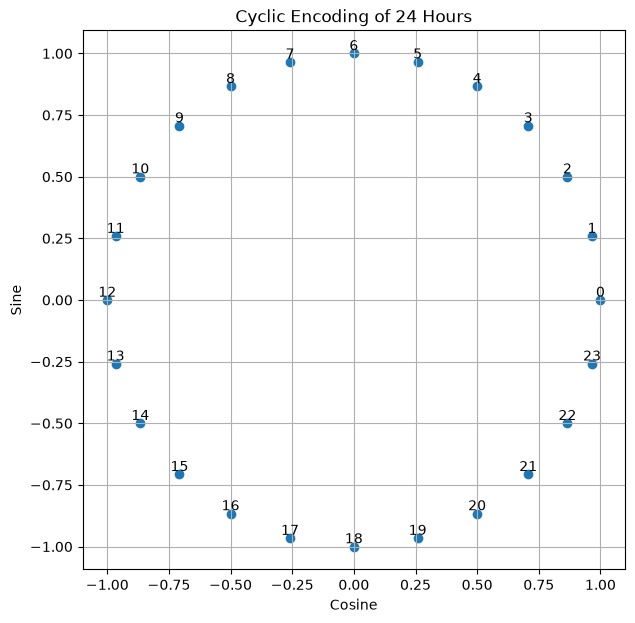

In [23]:
hours = np.arange(24)

hour_sin = np.sin(2 * np.pi * hours / 24)
hour_cos = np.cos(2 * np.pi * hours / 24)

plt.figure(figsize=(7, 7))

plt.scatter(hour_cos, hour_sin)

for hr in hours:
    plt.text(hour_cos[hr], hour_sin[hr], str(hr),
             ha='center', va='bottom')

plt.xlabel("Cosine")
plt.ylabel("Sine")
plt.title("Cyclic Encoding of 24 Hours")
plt.axis("equal")
plt.grid(True)
plt.show()

### 1.3 Comparing Hour Encoding Methods

We compare three encoding methods:

1. Raw Encoding: Treats hour as a normal numerical value.
2. Cyclic Encoding: Uses sine and cosine to represent the circular nature of hours.
3. One-Hot Encoding: Creates a separate column for each hour.

We use Linear Regression and TimeSeriesSplit to compare their performance.

In [24]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Common features used in all three models
common_features = ['yr', 'workingday', 'temp', 'mnth']

# Cyclic encoding function
def cyclic_hour(X):
    X = np.asarray(X, dtype=float)

    return np.hstack([
        np.sin(2 * np.pi * X / 24),
        np.cos(2 * np.pi * X / 24)
    ])

# 1. RAW ENCODING
raw_preprocessor = ColumnTransformer([
    ('hour', 'passthrough', ['hr']),
    ('other', 'passthrough', common_features)
])

# 2. CYCLIC ENCODING
cyclic_preprocessor = ColumnTransformer([
    ('hour', FunctionTransformer(cyclic_hour), ['hr']),
    ('other', 'passthrough', common_features)
])

# 3. ONE-HOT ENCODING
onehot_preprocessor = ColumnTransformer([
    ('hour', OneHotEncoder(handle_unknown='ignore'), ['hr']),
    ('other', 'passthrough', common_features)
])

# Create three pipelines
models = {
    'Raw': Pipeline([
        ('prep', raw_preprocessor),
        ('model', LinearRegression())
    ]),

    'Cyclic': Pipeline([
        ('prep', cyclic_preprocessor),
        ('model', LinearRegression())
    ]),

    'One-Hot': Pipeline([
        ('prep', onehot_preprocessor),
        ('model', LinearRegression())
    ])
}

# Time Series Cross Validation
tscv = TimeSeriesSplit(n_splits=5)

results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring='neg_root_mean_squared_error'
    )

    rmse = -scores

    results.append({
        'Encoding': name,
        'Mean RMSE': rmse.mean(),
        'Std RMSE': rmse.std()
    })

# Display comparison table
hour_results = pd.DataFrame(results)

hour_results = hour_results.sort_values('Mean RMSE')

print("Hour Encoding Comparison:")
display(hour_results.round(3))


Hour Encoding Comparison:


,Encoding,Mean RMSE,Std RMSE
2,One-Hot,112.368,19.884
1,Cyclic,132.489,23.655
0,Raw,145.388,25.270


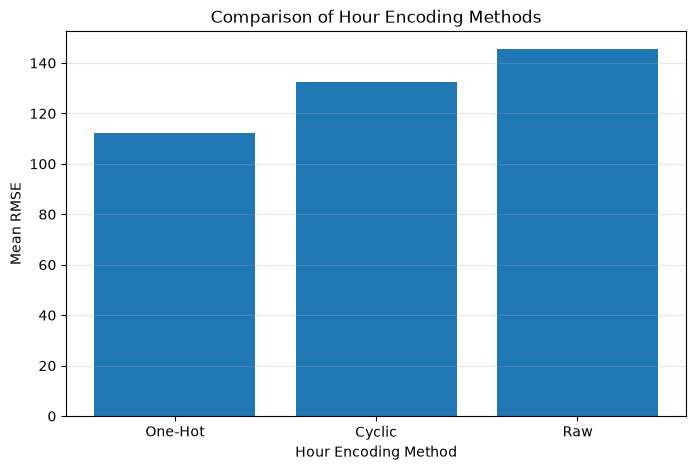

In [25]:
plt.figure(figsize=(8, 5))

plt.bar(
    hour_results['Encoding'],
    hour_results['Mean RMSE']
)

plt.xlabel("Hour Encoding Method")
plt.ylabel("Mean RMSE")
plt.title("Comparison of Hour Encoding Methods")
plt.grid(axis='y', alpha=0.3)

plt.savefig(
    '../results/figures/hour_encoding_comparison.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

### 1.4 Comparing Month Encoding Methods

We compare two methods of encoding months:

1. Raw Month Encoding
2. Cyclic Month Encoding (Sine and Cosine)

Cyclic encoding represents December and January as neighbouring
months, unlike raw numerical encoding.

We use Linear Regression and TimeSeriesSplit with 5 splits
to compare their performance using RMSE.

In [26]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

# Check that training data has been created
assert 'X_train' in globals() and 'y_train' in globals(), (
    "Run the data-loading and chronological train-test split cells first."
)

# Other features
other_features = ['yr', 'workingday', 'temp']

# Cyclic month encoding
def cyclic_month(X):
    X = np.asarray(X, dtype=float)
    return np.hstack([
        np.sin(2 * np.pi * X / 12),
        np.cos(2 * np.pi * X / 12)
    ])

# Raw month + One-Hot hour
raw_month_prep = ColumnTransformer([
    ('month', 'passthrough', ['mnth']),
    ('hour', OneHotEncoder(handle_unknown='ignore'), ['hr']),
    ('other', 'passthrough', other_features)
])

# Cyclic month + One-Hot hour
cyclic_month_prep = ColumnTransformer([
    ('month', FunctionTransformer(cyclic_month), ['mnth']),
    ('hour', OneHotEncoder(handle_unknown='ignore'), ['hr']),
    ('other', 'passthrough', other_features)
])

# Models
month_models = {
    'Raw Month': Pipeline([
        ('prep', raw_month_prep),
        ('model', LinearRegression())
    ]),
    'Cyclic Month': Pipeline([
        ('prep', cyclic_month_prep),
        ('model', LinearRegression())
    ])
}

# Cross-validation on training data only
tscv = TimeSeriesSplit(n_splits=5)
month_results = []

for name, model in month_models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring='neg_root_mean_squared_error'
    )

    rmse = -scores
    month_results.append({
        'Encoding': name,
        'Mean RMSE': rmse.mean(),
        'Std RMSE': rmse.std()
    })

month_results = pd.DataFrame(month_results)
display(month_results.round(3))


,Encoding,Mean RMSE,Std RMSE
0,Raw Month,112.368,19.884
1,Cyclic Month,113.764,19.319


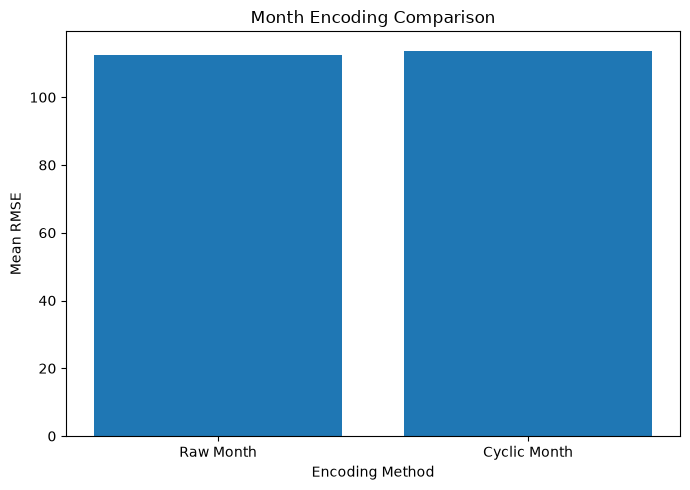

In [27]:

import matplotlib.pyplot as plt
import os

# Get updated month comparison results
plt.figure(figsize=(7, 5))

plt.bar(
    month_results['Encoding'],
    month_results['Mean RMSE']
)

plt.title('Month Encoding Comparison')
plt.xlabel('Encoding Method')
plt.ylabel('Mean RMSE')
plt.tight_layout()

# Save updated graph
os.makedirs('../results/figures', exist_ok=True)
plt.savefig(
    '../results/figures/month_encoding_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## Section 1.5: Test Set Evaluation (For Information Only)

The following results show the final performance of each encoding method on the test dataset. These results are for information only and are not used to select the best encoding.

In [28]:

from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

test_results = []

# Evaluate all three hour encoding models
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    test_results.append({
        'Model': f'Hour - {name}',
        'Test RMSE': rmse
    })

# Evaluate both month encoding models
for name, model in month_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    test_results.append({
        'Model': f'Month - {name} (One-Hot Hour)',
        'Test RMSE': rmse
    })

# Display final test results
test_results = pd.DataFrame(test_results)

display(test_results.round(3))


,Model,Test RMSE
0,Hour - Raw,190.556
1,Hour - Cyclic,169.674
2,Hour - One-Hot,140.771
3,Month - Raw Month (One-Hot Hour),140.771
4,Month - Cyclic Month (One-Hot Hour),140.858


### Conclusion

The comparison shows that One-Hot Encoding performs best for hour, followed by Cyclic Encoding and Raw Encoding.

One-Hot Encoding performs best because bike rental demand has two major peaks during the day: morning and evening, mainly due to commuting. It treats each hour separately, allowing the model to capture these different demand patterns.

Cyclic Encoding performs better than Raw Encoding because it understands that hour 23 is close to hour 0. However, sine and cosine create a smooth wave-like pattern, which may not capture both daily demand peaks effectively.

For month encoding, Raw Month performs slightly better than Cyclic Month (112.368 vs 113.764 RMSE). However, the difference is very small.

Therefore, One-Hot Encoding is the best choice for hour, while Raw Encoding is slightly better for month in this experiment.

## Section 2: Categorical Encoding, Scaling, and the Pipeline

In [7]:
import os
import pandas as pd

# Automatically find hour.csv whether it's in the current folder, src/, or ../src/
for path in ['hour.csv', './src/hour.csv', '../src/hour.csv', './hour.csv']:
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"Successfully loaded dataset from: {path}")
        break
else:
    raise FileNotFoundError("Could not find 'hour.csv'. Please check your folder location.")

# Split data
X = df.drop(columns=['cnt', 'casual', 'registered', 'dteday'])
y = df['cnt']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define preprocessor function
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_preprocessor():
    categorical_features = ['season', 'weathersit', 'weekday', 'hr', 'mnth']
    numeric_features = ['temp', 'atemp', 'hum', 'windspeed']
    
    return ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
            ('num', StandardScaler(), numeric_features)
        ],
        remainder='passthrough'
    )

# Build, fit, and predict
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

pipe = Pipeline([
    ('prep', build_preprocessor()),
    ('model', LinearRegression())
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
print("Pipeline fitted successfully and test predictions generated!")

Successfully loaded dataset from: hour.csv
Pipeline fitted successfully and test predictions generated!


### Pipeline Component Justifications
- **Season**: One-hot encoded because these are categorical groups with no numeric scale, and it partly overlaps with month.
- **Weathersit**: One-hot encoded because the progression from weather condition 1 to 4 is non-linear. `handle_unknown='ignore'` prevents crashes for unseen categories.
- **Weekday**: One-hot encoded since weekdays lack a natural numeric order for linear models, while binary indicators like `workingday` and `holiday` remain as passthrough.
- **Temperature, atemp, humidity, windspeed**: Scaled using `StandardScaler` so regularization penalties (Ridge/Lasso) weigh all features equally.
- **Year (`yr`)**: Kept as-is to preserve the linear growth trend from 2011 to 2012.

In [8]:
# 1. Check correlation between temp and atemp
print("--- Correlation between temp and atemp ---")
print(df[['temp', 'atemp']].corr())

# 2. Prove data leakage prevention (scaler mean vs full data mean)
scaler = pipe.named_steps['prep'].named_transformers_['num']
print("\n--- Scaler Mean (Train Only) ---")
print(scaler.mean_)
print("Full Dataset Mean (for comparison):")
print(X_train[['temp', 'atemp', 'hum', 'windspeed']].mean().values)

# 3. Print output feature names
feature_names = pipe.named_steps['prep'].get_feature_names_out()
print(f"\nTotal output features: {len(feature_names)}")
print(feature_names)

--- Correlation between temp and atemp ---
           temp     atemp
temp   1.000000  0.987672
atemp  0.987672  1.000000

--- Scaler Mean (Train Only) ---
[0.49739625 0.47618297 0.62701144 0.18982212]
Full Dataset Mean (for comparison):
[0.49739625 0.47618297 0.62701144 0.18982212]

Total output features: 59
['cat__season_1' 'cat__season_2' 'cat__season_3' 'cat__season_4'
 'cat__weathersit_1' 'cat__weathersit_2' 'cat__weathersit_3'
 'cat__weathersit_4' 'cat__weekday_0' 'cat__weekday_1' 'cat__weekday_2'
 'cat__weekday_3' 'cat__weekday_4' 'cat__weekday_5' 'cat__weekday_6'
 'cat__hr_0' 'cat__hr_1' 'cat__hr_2' 'cat__hr_3' 'cat__hr_4' 'cat__hr_5'
 'cat__hr_6' 'cat__hr_7' 'cat__hr_8' 'cat__hr_9' 'cat__hr_10' 'cat__hr_11'
 'cat__hr_12' 'cat__hr_13' 'cat__hr_14' 'cat__hr_15' 'cat__hr_16'
 'cat__hr_17' 'cat__hr_18' 'cat__hr_19' 'cat__hr_20' 'cat__hr_21'
 'cat__hr_22' 'cat__hr_23' 'cat__mnth_1' 'cat__mnth_2' 'cat__mnth_3'
 'cat__mnth_4' 'cat__mnth_5' 'cat__mnth_6' 'cat__mnth_7' 'cat__mnth_8'
 'c